In [11]:
import numpy as np
import math
import json
import statistics
from pathlib import Path
from matplotlib import pyplot as plt
%matplotlib inline

In [12]:
meas = {}
for f in Path('../data').glob('*.json'):
    d = json.loads(f.read_bytes())
    d['adc1'] = np.array(d['adc1'])
    d['adc2'] = np.array(d['adc2'])
    d['var1'] = np.array(d['var1'])
    d['var2'] = np.array(d['var2'])
    meas[d['meta']] = d

for n in sorted(meas):
    print(n)

74lvc_mesh_new_p0.3mm
74lvc_mesh_new_p0.4mm
74lvc_mesh_new_p0.6mm
74lvc_mesh_new_p1.0mm
74lvc_mesh_p0.3mm
74lvc_mesh_p0.3mm_flip
74lvc_mesh_p0.3mm_term
74lvc_mesh_p0.4mm
74lvc_mesh_p0.6mm
74lvc_mesh_p1.0mm
74lvc_new2_mesh_p0.3mm
74lvc_new2_mesh_p0.4mm
74lvc_new2_mesh_p0.6mm
74lvc_new2_mesh_p1.0mm
74lvc_new2_open
74lvc_new2_risetime
74lvc_new_mesh_p0.3mm
74lvc_new_mesh_p0.3mm_flip
74lvc_new_mesh_p0.3mm_term
74lvc_new_open
74lvc_open
long_sample_a_bwd
long_sample_a_bwd_term
long_sample_a_bwd_term_short
long_sample_a_fwd
long_sample_a_fwd_term
long_sample_a_fwd_term_short
long_sample_a_mod_flip
long_sample_a_mod_flip_term
long_sample_a_mod_flip_term_short
long_sample_a_mod_fwd
long_sample_a_mod_fwd_term
long_sample_a_mod_fwd_term_short
long_sample_b_bwd
long_sample_b_bwd_term
long_sample_b_fwd
long_sample_b_fwd_term
long_sample_b_fwd_term_short
long_sample_b_post_2mod_1
long_sample_b_post_2mod_10
long_sample_b_post_2mod_2
long_sample_b_post_2mod_3
long_sample_b_post_2mod_4
long_sample_b_p

1024
0.7473990650737986 0.8212164646241723 204
0.8103342575185438 0.8889700489509396 204
statistics: 0.743450060912541 0.7909857047231573 56
Rise time t_r = 47.458 ns
statistics: 0.8035581861223493 0.8457775456564767 56
Rise time t_r = 19.852 ns
Average rise time: 33.65473843208062


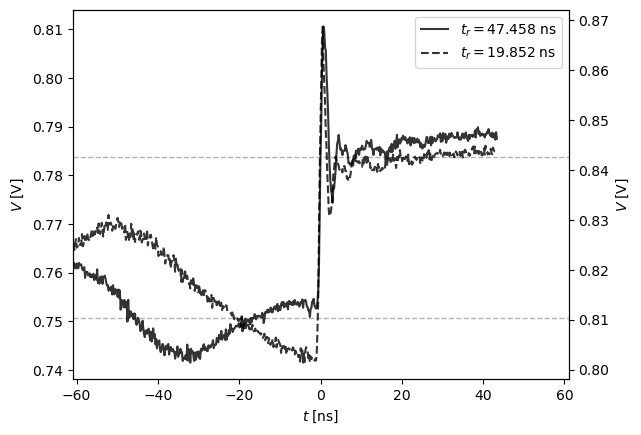

In [85]:
def plot_and_calc(run, ivl_start, ivl_end, ax=None, ylabel=True, grid=True):
    d = meas[run]
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))
    if ax is None:
        fig, ax = plt.subplots()
    ivl_w = ivl_end - ivl_start
    ivl = (ivl_start - ivl_w*0.5, ivl_end + ivl_w*0.5)

    t_slice = t[(ivl[0] <= t) & (t <= ivl[1])]
    adc1_slice = d['adc1'][(ivl[0] < t) & (t < ivl[1])]
    adc2_slice = d['adc2'][(ivl[0] < t) & (t < ivl[1])]
    print(len(t_slice))

    def find_offset(t, y):
        y_sorted = sorted(y)
        low = statistics.mean(y_sorted[:len(y_sorted)//5])
        high = statistics.mean(y_sorted[-len(y_sorted)//5:])
        print(low, high, len(y_sorted)//5)
        amp = high - low
        th = low + 0.5 * amp
        
        for t1, t2, y1, y2 in zip(t, t[1:], y, y[1:]):
            if y1 <= th < y2:
                return t1 + (t2 - t1) * (th - y1) / (y2 - y1)

    t1 = t_slice - find_offset(t_slice, adc1_slice)
    t2 = t_slice - find_offset(t_slice, adc2_slice)

    sel = (t1 >= -ivl_w/2) & (t1 <= ivl_w/2)
    a, b = sel.argmax(), len(sel) - sel[::-1].argmax()
    t1, adc1_slice = t1[a-1:b+1], adc1_slice[a-1:b+1]
    
    sel = (t2 >= -ivl_w/2) & (t2 <= ivl_w/2)
    a, b = sel.argmax(), len(sel) - sel[::-1].argmax()
    t2, adc2_slice = t2[a-1:b+1], adc2_slice[a-1:b+1]
    
    def edge_process(xs, ys, color):
        y_sorted = sorted(ys)
        low = statistics.mean(y_sorted[:len(y_sorted)//10])
        high = statistics.mean(y_sorted[-len(y_sorted)//10:])
        print('statistics:', low, high, len(y_sorted)//10)
        amp = high - low
        th_low = low + 0.15 * amp
        th_high = low + 0.85 * amp
    
        x_low, x_high = None, None
        state = -1
        for x1, x2, y1, y2 in zip(xs, xs[1:], ys, ys[1:]):
            if state == -1 and y1 < th_low and y2 > th_low:
                x_low = x1 + (x2 - x1) * (th_low - y1) / (y2 - y1)
                state = 0
            if state == 0 and y1 < th_high and y2 > th_high:
                state = 1
                x_high = x1 + (x2 - x1) * (th_high - y1) / (y2 - y1)
        #ax.axvline(x_low, color='red')
        #ax.axvline(x_high, color='blue')
        if x_high is None or x_low is None:
            return 0, 0, 1
        tr = x_high - x_low
        print(f'Rise time t_r = {tr:.3f} ns')
        #ax.axvline(x_low)
        #ax.axvline(x_high)
        return th_low, th_high, tr
        
    
    th_low1, th_high1, tr1 = edge_process(t1, adc1_slice, 'red')
    th_low2, th_high2, tr2 = edge_process(t2, adc2_slice, 'blue')

    if grid:
        ax.grid()
    else:
        ax.axhline(th_low1, linewidth=1, linestyle='--', color='black', alpha=0.3, zorder=-2)
        ax.axhline(th_high1, linewidth=1, linestyle='--', color='black', alpha=0.3, zorder=-2)
        
    #ax.plot(t, d['adc1'], color='red', alpha=0.8)
    #ax.twinx().plot(t, d['adc2'], color='blue', alpha=0.8)
    #ax.set_xlim(ivl)
    l1 = ax.plot(t1, adc1_slice, color='black', linestyle='-', alpha=0.8)
    tx = ax.twinx()
    l2 = tx.plot(t2, adc2_slice, color='black', linestyle='--', alpha=0.8)
    ax.set_xlim([-ivl_w/2, ivl_w/2])
    ax.set_xlabel(r'$t\;[\mathrm{ns}]$')
    if ylabel:
        ax.set_ylabel(r'$V\;[\mathrm{V}]$')
        tx.set_ylabel(r'$V\;[\mathrm{V}]$')
    ax.legend(l1 + l2, [
        fr'$t_r = {tr1:.3f}\;\mathrm{{ns}}$',
        fr'$t_r = {tr2:.3f}\;\mathrm{{ns}}$'])
    print('Average rise time:', (tr1+tr2)/2)
    
#plot_and_calc('pi3hdx_clipline_risetime_new', 87, 90)
plot_and_calc('max3748_new2_risetime', 8, 130, grid=False)
#plot_and_calc('run3_max3748_open', 98, 103)
#plot_and_calc('run3_74lvc_open', 97, 103)

214
1.2779597418648856 2.5903313814207563 42
0.8730813298906598 2.307233340241188 42
statistics: 1.271009645462036 2.4963875770568844 10
Rise time t_r = 1.055 ns
statistics: 0.8673178195953368 2.260366344451904 10
Rise time t_r = 0.977 ns
Average rise time: 1.0158313142590383
484
0.744375404715538 0.8143164831338469 96
0.8050688952207565 0.8751330886919474 96
statistics: 0.7483565902709961 0.7965309083461761 15
Rise time t_r = 0.755 ns
statistics: 0.8020668983459472 0.8503570175170898 15
Rise time t_r = 19.378 ns
Average rise time: 10.066391821783165
967
0.02842865089060729 0.056467505582829106 193
0.03819502845329324 0.07271053274882208 193
statistics: 0.0032493576407432554 0.05711862857525165 64
Rise time t_r = 0.366 ns
statistics: 0.004717393219470977 0.07685943163358248 64
Rise time t_r = 0.756 ns
Average rise time: 0.5609291456438499
967
0.006933149525538627 0.15674547657524188 193


TypeError: unsupported operand type(s) for -: 'float' and 'NoneType'

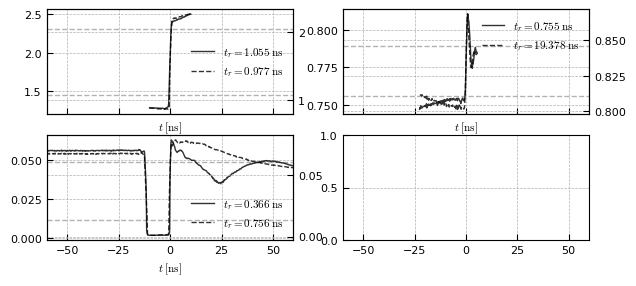

In [60]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(2, 2, sharex=True, figsize=[7, 3])
    axs = axs.flatten()

    #plot_and_calc('run3_74lvc_open', 97, 103, ax=axs[0], ylabel=None, grid=False)
    #plot_and_calc('run3_max3748_open', 98, 103, ax=axs[1], ylabel=None, grid=False)
    #plot_and_calc('run3_tdp0604_open', 97, 100, ax=axs[2], ylabel=None, grid=False)
    #plot_and_calc('pi3hdx_clipline_risetime_new', 87, 90, ax=axs[3], ylabel=None, grid=False)
    plot_and_calc('74lvc_new2_risetime', 75, 95, ax=axs[0], ylabel=None, grid=False)
    plot_and_calc('max3748_new2_risetime', 85, 130, ax=axs[1], ylabel=None, grid=False)
    plot_and_calc('tdp0604_new2_risetime', 0, 120, ax=axs[2], ylabel=None, grid=False)
    plot_and_calc('run3_pi3hdx_open', 0, 120, ax=axs[3], ylabel=None, grid=False)
    
    axs[0].set_xlabel(None)
    axs[1].set_xlabel(None)
    axs[2].set_xlabel(None)
    
    # axs[0].set_title('74LVC1G157 MUX Gate with Complimentary Outputs')
    # axs[1].set_title('MAX3748 Optical Network Limiting Amplifier')
    # axs[2].set_title('TDP0604 6 Gb/s HDMI Hybrid Redriver')
    # axs[3].set_title('PI3HDX12211 12 Gb/s HDMI Linear Redriver')
    
    axs[0].set_title('74LVC2G157')
    axs[1].set_title('MAX3748')
    axs[2].set_title('TDP0604')
    axs[3].set_title('PI3HDX12211')
    
    for ax in axs:
        ax.get_legend().set_loc('lower right')
    
    # Only do this on the last axis because of sharex=True
    ax.set_xlim([-1.8, 1.8])
    
    #for ax in axs:
    #    ax.grid()
    fig.tight_layout()

fig.savefig('../paper/fig_edge_risetime.pdf')

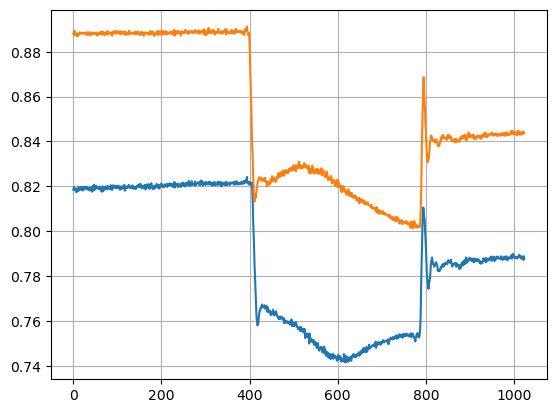

In [23]:

# just out of curiousity:
d = meas['max3748_new2_risetime']
fig, ax = plt.subplots()
ax.grid()
ax.plot(d['adc1'])
ax.plot(d['adc2'])